In [1]:
import torch
from torch import nn

from aif import DataModule, plot, Trainer, LinearRegression

import matplotlib.pyplot as plt

In [2]:
class Data(DataModule):
    def __init__(self, batch_size=16, T=1000, num_train=600, tau=4):
        super().__init__(batch_size)
        
        self.T = T
        self.num_train = num_train
        self.tau = tau

        self.time = torch.arange(1, T + 1, dtype=torch.float32)
        self.x = torch.sin(0.01 * self.time) + torch.randn(T) * 0.2

        self.features = None
        self.labels = None

    def get_dataloader(self, train):
        features = [self.x[i : self.T-self.tau+i] for i in range(self.tau)]
        
        self.features = torch.stack(features, 1)
        self.labels = self.x[self.tau:].reshape((-1, 1))
        
        i = slice(0, self.num_train) if train else slice(self.num_train, None)
        
        return self._get_tensorloader([self.features, self.labels], train, i)

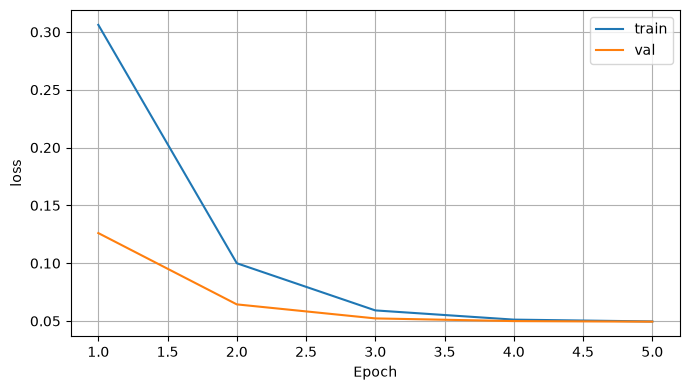

Epoch 5/5 | train_loss: 0.049609 | val_loss: 0.049434

In [3]:
data = Data()
model = LinearRegression(lr=0.01)

trainer = Trainer(max_epochs=5)
trainer.fit(model, data)

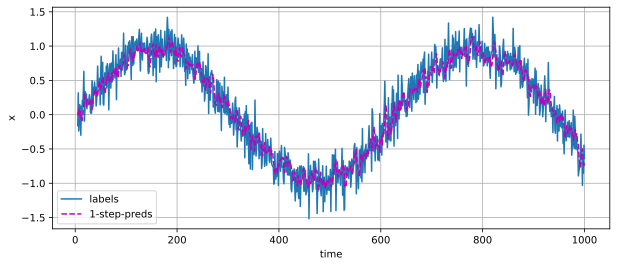

In [4]:
onestep_preds = model(data.features).detach().numpy()

plot(data.time[data.tau:], [data.labels, onestep_preds], 'time', 'x', legend=['labels', '1-step-preds'], figsize=(10, 4))

In [5]:
multistep_preds = torch.zeros(data.T)
multistep_preds[:] = data.x

for i in range(data.num_train + data.tau, data.T):
    multistep_preds[i] = model(
        multistep_preds[i - data.tau: i].reshape((1, -1))
    )

multistep_preds = multistep_preds.detach().numpy()

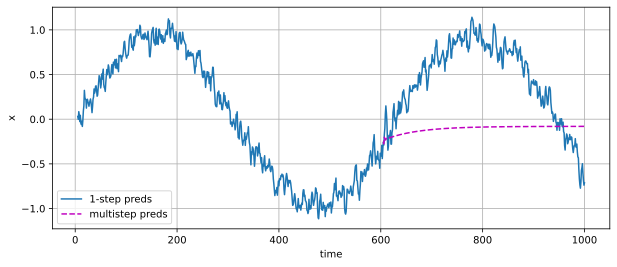

In [6]:
plot(
    [data.time[data.tau:], data.time[data.num_train + data.tau:]],
    [onestep_preds, multistep_preds[data.num_train + data.tau:]],
    'time', 'x',
    legend=['1-step preds', 'multistep preds'],
    figsize=(10, 4)
)

In [7]:
def k_step_pred(k):
    features = []
    for i in range(data.tau):
        features.append(data.x[i : i+data.T-data.tau-k+1])
    # The (i+tau)-th element stores the (i+1)-step-ahead predictions
    for i in range(k):
        preds = model(torch.stack(features[i : i+data.tau], 1))
        features.append(preds.reshape(-1))
    return features[data.tau:]

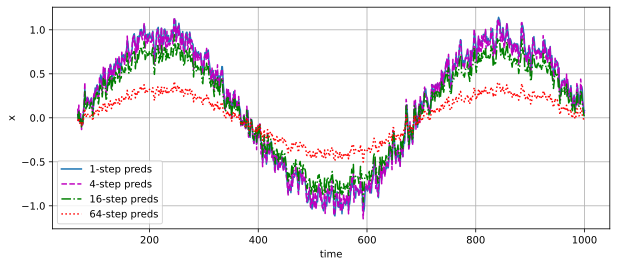

In [9]:
steps = (1, 4, 16, 64)
preds = k_step_pred(steps[-1])

plot(
    data.time[data.tau+steps[-1]-1:],
    [preds[k - 1].detach().numpy() for k in steps], 'time', 'x',
    legend=[f'{k}-step preds' for k in steps],
    figsize=(10, 4)
)